In [1]:
import pandas as pd
from safari_tools import SaFariAnnotation
from safari_vww import _read_manifest, _valid_loc

ann   = SaFariAnnotation.from_json("../data/hf_sa_fari/annotation/sa_fari_train.json")
ann_t = SaFariAnnotation.from_json("../data/hf_sa_fari/annotation/sa_fari_test.json")

# 1) what a video record looks like: which fields exist, and example location_id values
v0 = ann.video_names()[0]
print("fields of one video record:", list(ann.video_info(v0).keys()))
print("example location_id values:", [ann.video_info(v).get("location_id") for v in ann.video_names()[:8]], "\n")

# 2) in each release: how many videos share a location
for name, a in (("train release", ann), ("test release", ann_t)):
    loc = pd.Series({v: a.video_info(v).get("location_id") for v in a.video_names()})
    ok = loc[loc.map(_valid_loc)]
    per_loc = ok.value_counts()
    print(f"{name}: {len(loc):,} videos | {ok.nunique():,} locations | {len(loc) - len(ok)} videos without location")
    print(f"  videos per location: median {per_loc.median():.0f}, max {per_loc.max()} | "
          f"locations with 1 video: {(per_loc == 1).sum()} | with 10+ videos: {(per_loc >= 10).sum()}")

# 3) in the final frame lists: frames per group (location, or the video itself when there is no location)
def group(a, p):
    v = p.split("/")[0]; x = a.video_info(v).get("location_id")
    return f"loc:{x}" if _valid_loc(x) else f"vid:{v}"

print()
for name, a, path in (("training", ann, "split_train.csv"), ("validation", ann, "split_val.csv"),
                      ("test", ann_t, "manifest_vww_test.csv")):
    g = pd.Series([group(a, p) for p, _ in _read_manifest(f"../data/plans/{path}")]).value_counts()
    top5 = g.head(5)
    print(f"{name}: {g.sum():,} frames in {len(g)} groups | frames per group: median {g.median():.0f}, max {g.max():,}")
    print(f"  5 largest groups hold {top5.sum():,} frames ({100 * top5.sum() / g.sum():.1f}%): "
          + ", ".join(f"{k} ({n:,})" for k, n in top5.items()))

fields of one video record: ['id', 'video_name', 'file_names', 'height', 'width', 'length', 'location_id']
example location_id values: ['MS#164_sorted', 'arb_024', 'colpa_006', 'colpa_009', 'arb_001', 'barbs14', 'arb_039', 'SALED#2_B_sorted'] 

train release: 10,776 videos | 650 locations | 71 videos without location
  videos per location: median 1, max 380 | locations with 1 video: 437 | with 10+ videos: 154
test release: 833 videos | 91 locations | 4 videos without location
  videos per location: median 5, max 40 | locations with 1 video: 19 | with 10+ videos: 30

training: 58,082 frames in 552 groups | frames per group: median 9, max 3,234
  5 largest groups hold 11,667 frames (20.1%): loc:colpa_c03 (3,234), loc:arb_001 (3,115), loc:colpa_006 (2,099), loc:colpa_c92 (1,938), loc:colpa_005 (1,281)
validation: 10,488 frames in 120 groups | frames per group: median 9, max 1,239
  5 largest groups hold 4,989 frames (47.6%): loc:arb_007 (1,239), loc:copla_002 (1,180), loc:SHINTUYA_14_Terr

In [13]:
from collections import Counter
from safari_tools import SaFariAnnotation
from safari_vww import _valid_loc

total = with_id = 0
for s in ("train", "test"):
    a = SaFariAnnotation.from_json(f"../data/hf_sa_fari/annotation/sa_fari_{s}.json")
    vals = {v: a.video_info(v).get("location_id") for v in a.video_names()}
    bad = [v for v, x in vals.items() if not _valid_loc(x)]
    total += len(vals); with_id += len(vals) - len(bad)
    print(f"{s}: {len(vals):,} videos | with a valid location ID {len(vals) - len(bad):,} | without {len(bad)}")
    print("   value in place of the ID:", dict(Counter(repr(vals[v]) for v in bad)))
print(f"\nall releases: {total:,} videos = {with_id:,} with a valid ID + {total - with_id} without")

train: 10,776 videos | with a valid location ID 10,705 | without 71
   value in place of the ID: {'nan': 71}
test: 833 videos | with a valid location ID 829 | without 4
   value in place of the ID: {'nan': 4}

all releases: 11,609 videos = 11,534 with a valid ID + 75 without


In [3]:
import re
import pandas as pd
from safari_tools import SaFariAnnotation
from safari_vww import _valid_loc

rows = []
for rel in ("train", "test"):
    a = SaFariAnnotation.from_json(f"../data/hf_sa_fari/annotation/sa_fari_{rel}.json")
    for v in a.video_names():
        x = a.video_info(v).get("location_id")
        if _valid_loc(x):
            rows.append({"release": rel, "video": v, "loc": str(x)})
L = pd.DataFrame(rows)

# split each ID into a prefix (letters, separators) and a trailing number, if any
m = L["loc"].str.extract(r"^(.*?)[\s_\-]*(\d+)$")
L["prefix"] = m[0].fillna(L["loc"]).replace("", "(numeric only)")
L["num"] = pd.to_numeric(m[1], errors="coerce")

F = (L.groupby("prefix")
       .agg(ids=("loc", "nunique"), videos=("video", "nunique"),
            num_min=("num", "min"), num_max=("num", "max"),
            releases=("release", lambda s: "+".join(sorted(set(s)))),
            examples=("loc", lambda s: ", ".join(sorted(set(s))[:4])))
       .sort_values("ids", ascending=False))
F[["num_min", "num_max"]] = F[["num_min", "num_max"]].astype("Int64")

print(f"{L['loc'].nunique():,} location IDs in {len(F)} families "
      f"(train {L[L.release == 'train']['loc'].nunique():,}, test {L[L.release == 'test']['loc'].nunique():,})\n")
with pd.option_context("display.max_rows", None, "display.width", 200, "display.max_colwidth", 60):
    print(F.to_string())

741 location IDs in 608 families (train 650, test 91)

                               ids  videos  num_min   num_max    releases                                  examples
prefix                                                                                                             
arb                             72    2790        1        84  test+train        arb_001, arb_002, arb_003, arb_004
R                               17      48       13       517  test+train                    R013, R018, R050, R051
barbs                           16      36        1        23  test+train         barbs1, barbs10, barbs11, barbs14
colpa                           15     947        1        17  test+train  colpa007, colpa008, colpa_001, colpa_003
(numeric only)                   9       9  1209728  80681137       train    01209728, 02181419, 04143692, 13460462
campo                            6     128        1         9  test+train            campo1, campo2, campo3, campo4
0d               

In [4]:
import re
import pandas as pd
from safari_tools import SaFariAnnotation
from safari_vww import _valid_loc

rows = []
for rel in ("train", "test"):
    a = SaFariAnnotation.from_json(f"../data/hf_sa_fari/annotation/sa_fari_{rel}.json")
    for v in a.video_names():
        x = a.video_info(v).get("location_id")
        if _valid_loc(x):
            rows.append({"release": rel, "video": v, "loc": str(x)})
L = pd.DataFrame(rows)

def parse(s):
    m = re.match(r"^([A-Za-z]+)_(\d+)_(Arboreal|Terrestrial)$", s)
    if m:                                   return "site_station_mount", m[1], f"{m[1]}_{m[2]}", m[3]
    m = re.match(r"^([A-Za-z]+)#", s)
    if m:                                   return "project#camera", m[1], s, None
    if re.fullmatch(r"[0-9a-f]{8}", s):     return "8-char code", "(code)", s, None
    m = re.match(r"^([A-Za-z]+)", s)
    if m:                                   return "prefix+number", m[1], s, None
    return "other", s, s, None

L[["format", "family", "station", "mount"]] = L["loc"].apply(lambda s: pd.Series(parse(s)))

# 1) formats and families
F = (L.groupby(["format", "family"])
       .agg(ids=("loc", "nunique"), videos=("video", "nunique"),
            ids_train=("loc", lambda s: s[L.loc[s.index, "release"] == "train"].nunique()),
            ids_test=("loc", lambda s: s[L.loc[s.index, "release"] == "test"].nunique()),
            examples=("loc", lambda s: ", ".join(sorted(set(s))[:3])))
       .sort_values(["format", "ids"], ascending=[True, False]))
print(f"{L['loc'].nunique():,} location IDs | videos per ID: "
      f"{(L.groupby('loc').video.nunique() == 1).sum():,} IDs have a single video\n")
with pd.option_context("display.max_rows", None, "display.width", 200, "display.max_colwidth", 60):
    print(F.to_string(), "\n")

# 2) stations with an arboreal and a terrestrial camera, and how they fall across releases
S = L[L["format"] == "site_station_mount"].groupby("station").agg(
        mounts=("mount", lambda s: "+".join(sorted(set(s)))),
        releases=("release", lambda s: "+".join(sorted(set(s)))))
both = S[S.mounts == "Arboreal+Terrestrial"]
split = both[both.releases == "test+train"]
print(f"stations (SITE_n): {len(S)} | with both cameras: {len(both)} | "
      f"both cameras but split between train and test: {len(split)}")
print("  e.g.", ", ".join(split.index[:10]))

741 location IDs | videos per ID: 456 IDs have a single video

                             ids  videos  ids_train  ids_test                                                             examples
format             family                                                                                                         
8-char code        (code)    429     429        426         3                                         000add1f, 01209728, 018bcdfd
prefix+number      arb        72    2790         68         4                                            arb_001, arb_002, arb_003
                   R          17      48          7        10                                                     R013, R018, R050
                   colpa      17    1474         14         3                                        colpa007, colpa008, colpa_001
                   barbs      16      36         13         3                                             barbs1, barbs10, barbs11
                   c

In [7]:
import shutil
import pandas as pd
from pathlib import Path
from PIL import Image, ImageDraw
from safari_vww import _read_manifest

FAMILIES = ["arb", "R", "colpa", "barbs", "campo", "MS", "MLC", "ROMERO", "SHINTUYA", "DIAMANTE"]
MAX_IDS = 24                                        # IDs per family (all IDs if the family has fewer)
OUT = Path("../locations")
SRC = {s: Path(f"../data/google_sa_fari/sa_fari/sa_fari_{s}/JPEGImages_6fps") for s in ("train", "test")}

# sampled (downloaded) frames of each video
frames = {s: {} for s in SRC}
for s in SRC:
    for p, _ in _read_manifest(f"../data/plans/manifest_{s}_download_plan.csv"):
        frames[s].setdefault(p.split("/")[0], []).append(p)

for fam in FAMILIES:
    d = OUT / fam; d.mkdir(parents=True, exist_ok=True)
    ids = sorted(L.loc[L.family == fam, "loc"].unique())
    if len(ids) > MAX_IDS:                          # spread the picks over the sorted IDs
        ids = [ids[round(i * (len(ids) - 1) / (MAX_IDS - 1))] for i in range(MAX_IDS)]
    thumbs = []
    for loc in ids:
        r = L[L["loc"] == loc].sort_values("video").iloc[0]           # first video of this location
        fs = sorted(frames[r.release].get(r.video, []))
        if not fs:
            continue
        p = fs[len(fs) // 2]                                           # middle sampled frame
        dst = d / f"{loc}__{r.release}__{p.replace('/', '_')}"
        shutil.copy(SRC[r.release] / p, dst)
        thumbs.append((f"{loc} ({r.release})", dst))

    # one contact sheet per family, to look at all IDs at once
    W, H, C = 320, 200, 4
    sheet = Image.new("RGB", (W * C, (H + 18) * ((len(thumbs) + C - 1) // C)), "white")
    for i, (label, f) in enumerate(thumbs):
        im = Image.open(f).convert("RGB"); im.thumbnail((W, H))
        x, y = (i % C) * W, (i // C) * (H + 18)
        sheet.paste(im, (x, y + 18)); ImageDraw.Draw(sheet).text((x + 4, y + 3), label, fill="black")
    sheet.save(d / f"_{fam}_sheet.jpg", quality=90)
    print(f"{fam:9} {len(thumbs):2} IDs -> {d}")

arb       24 IDs -> ../locations/arb
R         17 IDs -> ../locations/R
colpa     17 IDs -> ../locations/colpa
barbs     16 IDs -> ../locations/barbs
campo      6 IDs -> ../locations/campo
MS        24 IDs -> ../locations/MS
MLC       24 IDs -> ../locations/MLC
ROMERO    23 IDs -> ../locations/ROMERO
SHINTUYA  21 IDs -> ../locations/SHINTUYA
DIAMANTE  19 IDs -> ../locations/DIAMANTE


In [9]:
import shutil
from pathlib import Path
from PIL import Image, ImageDraw

per_id = L.groupby("loc").agg(videos=("video", "nunique"), family=("family", "first"),
                              release=("release", "first")).sort_values("videos", ascending=False)

# 1) how many videos share a location ID
bins = pd.cut(per_id.videos, [0, 1, 5, 20, 100, 10_000], labels=["1", "2-5", "6-20", "21-100", ">100"])
print("location IDs by number of videos:")
print(bins.value_counts().sort_index().to_string(), "\n")
print("largest location IDs:")
print(per_id.head(10).to_string(), "\n")

# 2) visual check: several videos of the same location ID side by side
OUT = Path("../locations/same_id")
picks = per_id[per_id.videos >= 8].groupby("family").head(1).head(6)      # one large ID per family, up to 6
for loc, r in picks.iterrows():
    d = OUT / loc.replace("#", "_"); d.mkdir(parents=True, exist_ok=True)
    vids = sorted(L.loc[L["loc"] == loc, "video"].unique())
    vids = [vids[round(i * (len(vids) - 1) / 7)] for i in range(8)]     # 8 videos spread over the ID
    thumbs = []
    for v in vids:
        fs = sorted(frames[r.release].get(v, []))
        if fs:
            p = fs[len(fs) // 2]
            dst = d / p.replace("/", "_"); shutil.copy(SRC[r.release] / p, dst); thumbs.append((v, dst))
    W, H, C = 320, 200, 4
    sheet = Image.new("RGB", (W * C, (H + 18) * 2), "white")
    for i, (v, f) in enumerate(thumbs):
        im = Image.open(f).convert("RGB"); im.thumbnail((W, H))
        x, y = (i % C) * W, (i // C) * (H + 18)
        sheet.paste(im, (x, y + 18)); ImageDraw.Draw(sheet).text((x + 4, y + 3), v, fill="black")
    sheet.save(d / "_sheet.jpg", quality=90)
    print(f"{loc:28} {r.videos:4} videos ({r.release}) -> {d}")

location IDs by number of videos:
videos
1         456
2-5        69
6-20       71
21-100    116
>100       29 

largest location IDs:
                         videos    family release
loc                                              
arb_001                     380       arb   train
colpa_c03                   329     colpa   train
colpa_003                   277     colpa   train
colpa_006                   248     colpa   train
SHINTUYA_14_Terrestrial     224  SHINTUYA   train
colpa_c92                   198     colpa   train
arb_070                     176       arb   train
SALED#2_B_sorted            167     SALED   train
arb_053                     165       arb   train
MS#7_sorted                 161        MS   train 

arb_001                       380 videos (train) -> ../locations/same_id/arb_001
colpa_c03                     329 videos (train) -> ../locations/same_id/colpa_c03
SHINTUYA_14_Terrestrial       224 videos (train) -> ../locations/same_id/SHINTUYA_14_Terrestrial
SA

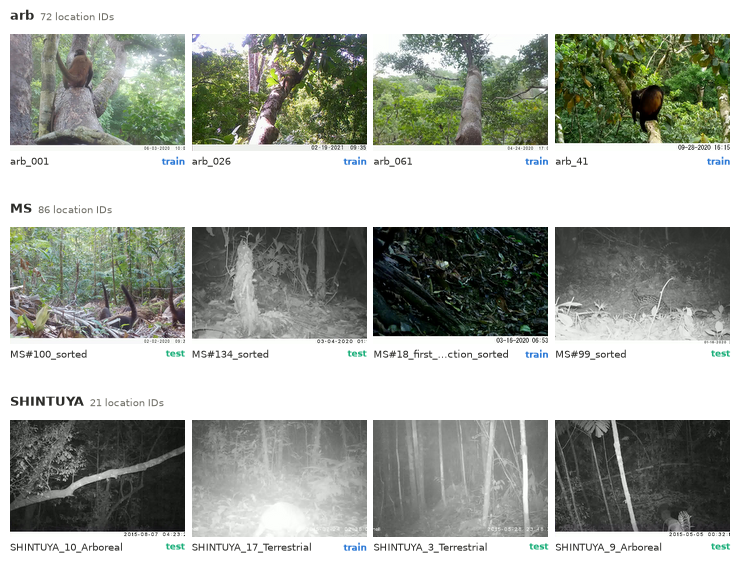

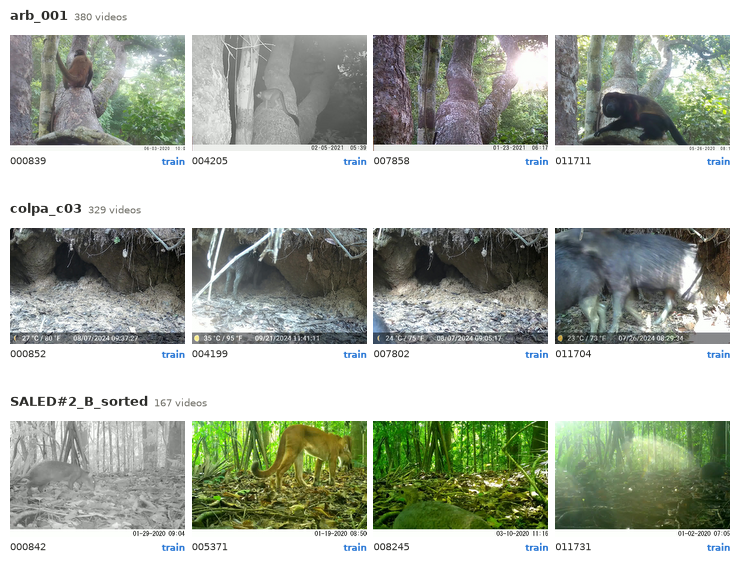

saved to /home/kitcovid-0738/safari/code/display/locations


In [12]:
import os
from pathlib import Path
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from safari_tools import SaFariAnnotation
from safari_vww import _read_manifest, _valid_loc

OUT = Path("display/locations"); OUT.mkdir(parents=True, exist_ok=True)
SRC = {s: Path(f"../data/google_sa_fari/sa_fari/sa_fari_{s}/JPEGImages_6fps") for s in ("train", "test")}

# ---------- style (same as the other figures) ----------
FONT = "Inter" if "Inter" in {f.name for f in font_manager.fontManager.ttflist} else "DejaVu Sans"
mpl.rcParams.update({"font.family": FONT, "font.size": 8, "pdf.fonttype": 42, "svg.fonttype": "none"})
INK, MUTED = "#2b2b28", "#6f6e66"
SPLIT_COL = {"train": "#2a78d6", "test": "#1baf7a"}     # same split colours as the area figure
ASPECT = 3 / 2                                          # every tile is centre-cropped to 3:2
NCOL, WIDTH = 4, 7.2                                    # double-column width

# ---------- data: location ID of every video, sampled frames of every video ----------
loc, rel, frames = {}, {}, {}
for s in SRC:
    a = SaFariAnnotation.from_json(f"../data/hf_sa_fari/annotation/sa_fari_{s}.json")
    for v in a.video_names():
        x = a.video_info(v).get("location_id")
        if _valid_loc(x):
            loc[v], rel[v] = str(x), s
    for p, _ in _read_manifest(f"../data/plans/manifest_{s}_download_plan.csv"):
        frames.setdefault(p.split("/")[0], []).append(p)

def middle_frame(v):
    fs = sorted(frames.get(v, []))
    return SRC[rel[v]] / fs[len(fs) // 2] if fs else None

def spread(items, k):                                   # k items evenly spread over a sorted list
    items = sorted(items)
    return items if len(items) <= k else [items[round(i * (len(items) - 1) / (k - 1))] for i in range(k)]

def crop(path, aspect=ASPECT, max_w=900):
    with Image.open(path) as im:
        im = im.convert("RGB")
        w, h = im.size
        if w / h > aspect:                              # too wide: trim the sides
            nw = int(h * aspect); im = im.crop(((w - nw) // 2, 0, (w - nw) // 2 + nw, h))
        else:                                           # too tall: trim top and bottom
            nh = int(w / aspect); im = im.crop((0, (h - nh) // 2, w, (h - nh) // 2 + nh))
        im.thumbnail((max_w, max_w))
        return np.asarray(im)

def distinct(names):                                    # drop the prefix all names in a row share
    pre = os.path.commonprefix(names) if len(names) > 1 else ""
    return [(n[len(pre):].lstrip("_-/ ") or n) for n in names]

def short(s, n=26):
    return s if len(s) <= n else s[: n // 2 - 1] + "…" + s[-(n // 2 - 1):]

# ---------- grid: one header per row, one caption + split tag per tile ----------
def grid(rows, headers, path):
    tile_h = WIDTH / NCOL / ASPECT
    fig, axes = plt.subplots(len(rows), NCOL, figsize=(WIDTH, len(rows) * (tile_h + 0.62)),
                             squeeze=False)
    fig.subplots_adjust(left=0, right=1, top=1 - 0.30 / fig.get_figheight(), bottom=0.02,
                        wspace=0.04, hspace=0.62)
    for r, (cells, header) in enumerate(zip(rows, headers)):
        axes[r, 0].text(0, 1.10, header[0], transform=axes[r, 0].transAxes, ha="left", va="bottom",
                        fontsize=9, fontweight="semibold", color=INK)
        if header[1]:
            axes[r, 0].text(0, 1.10, f"   {header[1]}", transform=axes[r, 0].transAxes, ha="left",
                            va="bottom", fontsize=7.5, color=MUTED)
        for c in range(NCOL):
            ax = axes[r, c]; ax.set_axis_off()
            if c >= len(cells) or cells[c][0] is None:
                continue
            img, caption, split = cells[c]
            ax.imshow(crop(img), interpolation="lanczos")
            ax.text(0, -0.05, short(caption), transform=ax.transAxes, ha="left", va="top",
                    fontsize=7, color=INK)
            ax.text(1, -0.05, split, transform=ax.transAxes, ha="right", va="top",
                    fontsize=6.5, color=SPLIT_COL[split], fontweight="semibold")
    # second header line sits after the bold one: measure it once drawn
    fig.canvas.draw()
    for r, header in enumerate(headers):
        if header[1]:
            bold, light = axes[r, 0].texts[0], axes[r, 0].texts[1]
            bb = bold.get_window_extent().transformed(axes[r, 0].transAxes.inverted())
            light.set_x(bb.x1); light.set_text(f"  {header[1]}")
    fig.savefig(path.with_suffix(".svg"), bbox_inches="tight", dpi=300)
    fig.savefig(path.with_suffix(".png"), bbox_inches="tight", dpi=300)
    plt.show()

# ---------- Figure A: 4 different location IDs from each of three projects ----------
by_id = {}
for v, x in loc.items():
    by_id.setdefault(x, []).append(v)
FAM = {"arb": lambda x: x.startswith("arb_"), "MS": lambda x: x.startswith("MS#"),
       "SHINTUYA": lambda x: x.startswith("SHINTUYA_")}
rows, headers = [], []
for fam, test in FAM.items():
    ids = spread([x for x in by_id if test(x)], NCOL)
    rows.append([(middle_frame(sorted(by_id[x])[0]), x, rel[sorted(by_id[x])[0]]) for x in ids])
    headers.append((fam, f"{sum(test(x) for x in by_id)} location IDs"))
grid(rows, headers, OUT / "locations_by_project")

# ---------- Figure B: 4 different videos from each of three location IDs ----------
IDS = ["arb_001", "colpa_c03", "SALED#2_B_sorted"]
rows = []
for x in IDS:
    vids = spread(by_id[x], NCOL)
    rows.append([(middle_frame(v), v.replace("sa_fari_", ""), rel[v]) for v in vids])
headers = [(x, f"{len(by_id[x])} videos") for x in IDS]
grid(rows, headers, OUT / "videos_same_location")
print("saved to", OUT.resolve())

In [14]:
import json
import pandas as pd
from safari_tools import SaFariAnnotation
from safari_vww import _valid_loc

ann = SaFariAnnotation(json.load(open("../data/hf_sa_fari/annotation/sa_fari_test.json")))

def grupo(v):
    loc = ann.video_info(v).get("location_id")
    return f"loc:{loc}" if _valid_loc(loc) else f"vid:{v}"

# 1) release completo (833 vídeos)
rel = pd.Series({v["video_name"]: grupo(v["video_name"]) for v in ann.d["videos"]})

# 2) amostra de 10% e 3) frames rotulados (5.061)
amo = pd.read_csv("../data/plans/manifest_test_download_plan.csv")
vww = pd.read_csv("../data/plans/manifest_vww_test.csv")
for d in (amo, vww):
    d["grupo"] = d["path"].str.split("/").str[0].map(rel)

def resumo(nome, g):
    g = pd.Series(g).unique()
    n_loc = sum(x.startswith("loc:") for x in g)
    print(f"{nome:>9}: {n_loc} location IDs + {len(g) - n_loc} vídeos sem ID = {len(g)} grupos")

resumo("release", rel)
resumo("amostra", amo["grupo"])
resumo("rotulado", vww["grupo"])

print("\nGrupos do release ausentes nos frames rotulados:")
for g in sorted(set(rel) - set(vww["grupo"])):
    print(f"  {g}: {(rel == g).sum()} vídeos, {amo['grupo'].eq(g).sum()} frames na amostra")

  release: 91 location IDs + 4 vídeos sem ID = 95 grupos
  amostra: 91 location IDs + 4 vídeos sem ID = 95 grupos
 rotulado: 89 location IDs + 2 vídeos sem ID = 91 grupos

Grupos do release ausentes nos frames rotulados:
  loc:DIAMANTE_13_Arboreal: 1 vídeos, 8 frames na amostra
  loc:SHINTUYA_9_Arboreal: 1 vídeos, 8 frames na amostra
  vid:sa_fari_000113: 1 vídeos, 8 frames na amostra
  vid:sa_fari_000364: 1 vídeos, 8 frames na amostra
